In [2]:
import pandas as pd
import numpy as np

train = pd.read_csv('/kaggle/input/datasets/julian3833/jigsaw-toxic-comment-classification-challenge/train.csv')

test = pd.read_csv('/kaggle/input/datasets/julian3833/jigsaw-toxic-comment-classification-challenge/test.csv')

test_labels = pd.read_csv('/kaggle/input/datasets/julian3833/jigsaw-toxic-comment-classification-challenge/test_labels.csv')

sample_submission = pd.read_csv('/kaggle/input/datasets/julian3833/jigsaw-toxic-comment-classification-challenge/sample_submission.csv')

In [3]:
print("Train Shape:", train.shape)
print("Test Shape:", test.shape)
print("Test Labels Shape:", test_labels.shape)

print("\nTrain Columns:")
print(train.columns.tolist())

train.head()

Train Shape: (159571, 8)
Test Shape: (153164, 2)
Test Labels Shape: (153164, 7)

Train Columns:
['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   id             159571 non-null  object
 1   comment_text   159571 non-null  object
 2   toxic          159571 non-null  int64 
 3   severe_toxic   159571 non-null  int64 
 4   obscene        159571 non-null  int64 
 5   threat         159571 non-null  int64 
 6   insult         159571 non-null  int64 
 7   identity_hate  159571 non-null  int64 
dtypes: int64(6), object(2)
memory usage: 9.7+ MB


In [5]:
print("Missing Values:")
print(train.isnull().sum())

print("\nDuplicate Rows:", train.duplicated().sum())

print("\nDuplicate Comments:", train['comment_text'].duplicated().sum())

Missing Values:
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64

Duplicate Rows: 0

Duplicate Comments: 0


In [6]:
target_cols = [
    'toxic',
    'severe_toxic',
    'obscene',
    'threat',
    'insult',
    'identity_hate'
]

print(train[target_cols].sum())

toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
dtype: int64


In [7]:
for col in target_cols:

    positive = train[col].sum()
    negative = len(train) - positive

    print(f"\n{col}")
    print("Positive:", positive)
    print("Negative:", negative)
    print("Positive Percentage:", round(positive / len(train) * 100, 2), "%")


toxic
Positive: 15294
Negative: 144277
Positive Percentage: 9.58 %

severe_toxic
Positive: 1595
Negative: 157976
Positive Percentage: 1.0 %

obscene
Positive: 8449
Negative: 151122
Positive Percentage: 5.29 %

threat
Positive: 478
Negative: 159093
Positive Percentage: 0.3 %

insult
Positive: 7877
Negative: 151694
Positive Percentage: 4.94 %

identity_hate
Positive: 1405
Negative: 158166
Positive Percentage: 0.88 %


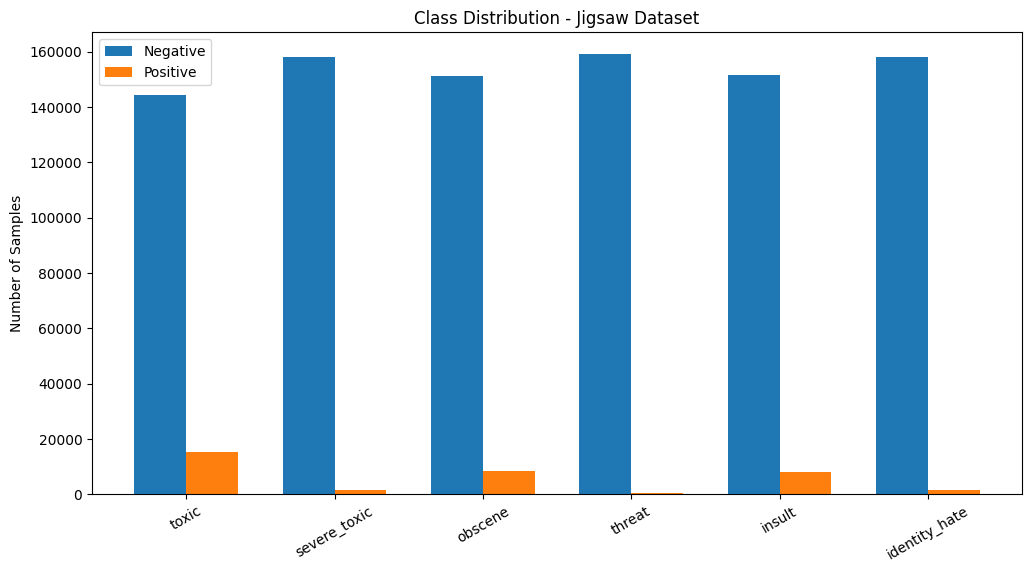

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

positive_counts = train[target_cols].sum()
negative_counts = len(train) - positive_counts

x = np.arange(len(target_cols))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(x - width/2, negative_counts, width, label='Negative')
plt.bar(x + width/2, positive_counts, width, label='Positive')

plt.xticks(x, target_cols, rotation=30)
plt.ylabel("Number of Samples")
plt.title("Class Distribution - Jigsaw Dataset")
plt.legend()
plt.show()

In [9]:
train['label_count'] = train[target_cols].sum(axis=1)

print(train['label_count'].value_counts().sort_index())

label_count
0    143346
1      6360
2      3480
3      4209
4      1760
5       385
6        31
Name: count, dtype: int64


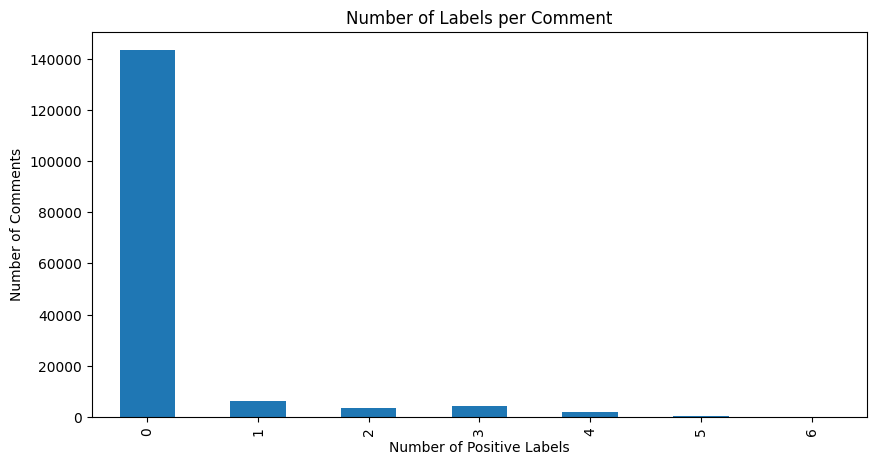

In [10]:
train['label_count'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Number of Labels per Comment")
plt.xlabel("Number of Positive Labels")
plt.ylabel("Number of Comments")
plt.show()

In [11]:
!pip install -q datasets

In [13]:
from datasets import load_dataset
dataset = load_dataset("google/civil_comments")

README.md:   0%|          | 0.00/7.73k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  194MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.8MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1804874 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/97320 [00:00<?, ? examples/s]

In [15]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 1804874
    })
    validation: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 97320
    })
    test: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 97320
    })
})


In [16]:
civil = dataset['train'].to_pandas()

print("Civil Comments Shape:", civil.shape)

civil.head()

Civil Comments Shape: (1804874, 8)


,text,toxicity,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
0,"This is so cool. It's like, 'would you want yo...",0.000000,0.000000,0.0,0.0,0.00000,0.000000,0.0
1,Thank you!! This would make my life a lot less...,0.000000,0.000000,0.0,0.0,0.00000,0.000000,0.0
2,This is such an urgent design problem; kudos t...,0.000000,0.000000,0.0,0.0,0.00000,0.000000,0.0
3,Is this something I'll be able to install on m...,0.000000,0.000000,0.0,0.0,0.00000,0.000000,0.0
4,haha you guys are a bunch of losers.,0.893617,0.021277,0.0,0.0,0.87234,0.021277,0.0


In [18]:
civil.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1804874 entries, 0 to 1804873
Data columns (total 8 columns):
 #   Column           Dtype  
---  ------           -----  
 0   text             object 
 1   toxicity         float32
 2   severe_toxicity  float32
 3   obscene          float32
 4   threat           float32
 5   insult           float32
 6   identity_attack  float32
 7   sexual_explicit  float32
dtypes: float32(7), object(1)
memory usage: 62.0+ MB


In [19]:
print("Columns:")
print(civil.columns.tolist())

print("\nData Types:")
print(civil.dtypes)

print("\nMissing Values:")
print(civil.isnull().sum())

print("\nDuplicate Rows:")
print(civil.duplicated().sum())

print("\nDuplicate Comments:")
print(civil['text'].duplicated().sum())

Columns:
['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']

Data Types:
text                object
toxicity           float32
severe_toxicity    float32
obscene            float32
threat             float32
insult             float32
identity_attack    float32
sexual_explicit    float32
dtype: object

Missing Values:
text               0
toxicity           0
severe_toxicity    0
obscene            0
threat             0
insult             0
identity_attack    0
sexual_explicit    0
dtype: int64

Duplicate Rows:
17955

Duplicate Comments:
24051


In [21]:
civil_labels = [
    'toxicity',
    'severe_toxicity',
    'obscene',
    'threat',
    'insult',
    'identity_attack',
    'sexual_explicit'
]
print(civil[civil_labels].describe().T)

                     count      mean       std  min  25%  50%       75%  max
toxicity         1804874.0  0.103017  0.197196  0.0  0.0  0.0  0.166667  1.0
severe_toxicity  1804874.0  0.004582  0.022708  0.0  0.0  0.0  0.000000  1.0
obscene          1804874.0  0.013877  0.064103  0.0  0.0  0.0  0.000000  1.0
threat           1804874.0  0.009311  0.049047  0.0  0.0  0.0  0.000000  1.0
insult           1804874.0  0.081153  0.176721  0.0  0.0  0.0  0.090909  1.0
identity_attack  1804874.0  0.022636  0.079204  0.0  0.0  0.0  0.000000  1.0
sexual_explicit  1804874.0  0.006606  0.044969  0.0  0.0  0.0  0.000000  1.0


In [22]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for label in civil_labels:

    for threshold in thresholds:

        positive = (civil[label] >= threshold).sum()
        negative = len(civil) - positive

        results.append({
            'Label': label,
            'Threshold': threshold,
            'Positive': positive,
            'Negative': negative,
            'Positive_Percentage': round(
                positive / len(civil) * 100, 2
            )
        })

threshold_df = pd.DataFrame(results)

threshold_df

,Label,Threshold,Positive,Negative,Positive_Percentage
0,toxicity,0.3,266089,1538785,14.74
1,toxicity,0.4,201476,1603398,11.16
2,toxicity,0.5,144334,1660540,8.00
3,toxicity,0.6,96410,1708464,5.34
4,toxicity,0.7,45451,1759423,2.52
5,severe_toxicity,0.3,494,1804380,0.03
6,severe_toxicity,0.4,75,1804799,0.00
7,severe_toxicity,0.5,13,1804861,0.00
8,severe_toxicity,0.6,3,1804871,0.00
9,severe_toxicity,0.7,1,1804873,0.00


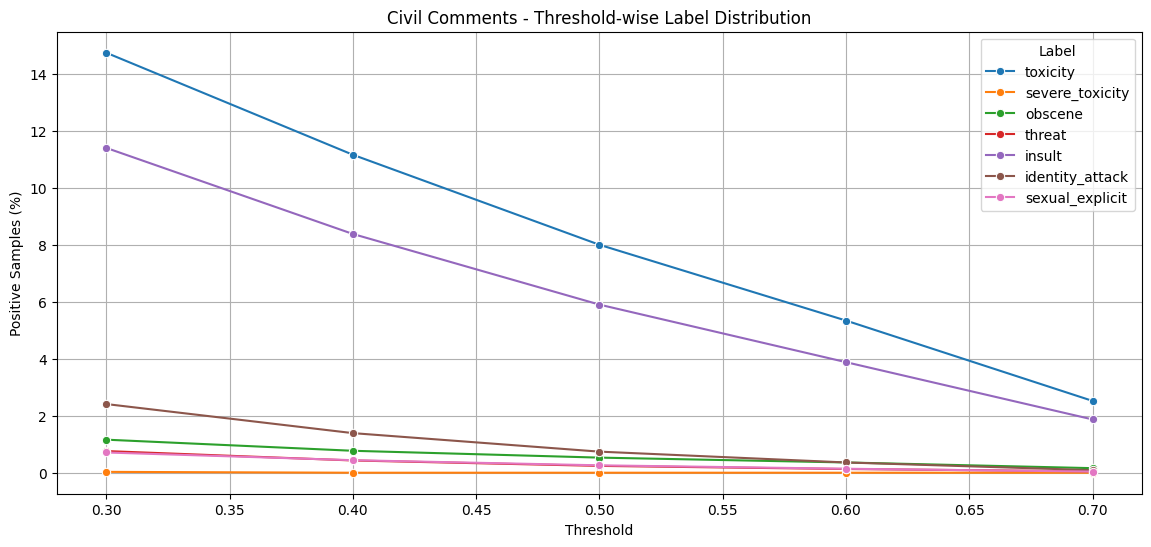

In [23]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=threshold_df,
    x='Threshold',
    y='Positive_Percentage',
    hue='Label',
    marker='o'
)

plt.title("Civil Comments - Threshold-wise Label Distribution")
plt.ylabel("Positive Samples (%)")
plt.grid(True)
plt.show()

In [24]:
binary_labels = (
    civil[civil_labels] >= 0.5
).astype(int)

civil['label_count'] = binary_labels.sum(axis=1)

print(
    civil['label_count']
    .value_counts()
    .sort_index()
)

label_count
0    1656327
1      26477
2     110980
3      10012
4       1011
5         60
6          6
7          1
Name: count, dtype: int64


In [25]:
civil['char_length'] = civil['text'].str.len()

civil['word_count'] = civil['text'].str.split().str.len()

print(civil[['char_length', 'word_count']].describe())

        char_length    word_count
count  1.804874e+06  1.804874e+06
mean   2.972343e+02  5.127690e+01
std    2.691966e+02  4.617811e+01
min    1.000000e+00  1.000000e+00
25%    9.400000e+01  1.600000e+01
50%    2.020000e+02  3.500000e+01
75%    4.140000e+02  7.200000e+01
max    1.906000e+03  3.170000e+02


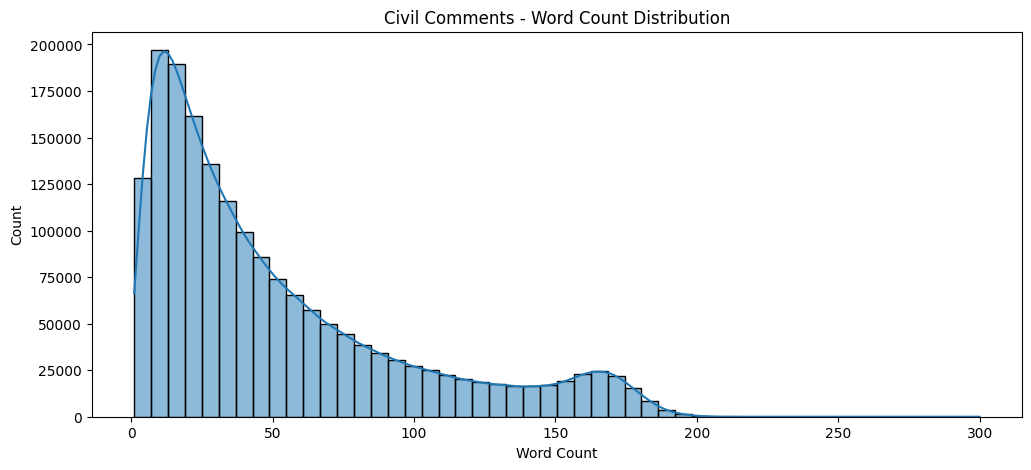

In [26]:
plt.figure(figsize=(12, 5))

sns.histplot(
    civil['word_count'].clip(upper=300),
    bins=50,
    kde=True
)

plt.title("Civil Comments - Word Count Distribution")
plt.xlabel("Word Count")
plt.show()

In [27]:
for label in civil_labels:

    print(f"\n========== {label.upper()} ==========")

    samples = civil[civil[label] >= 0.5].sample(
        n=min(3, (civil[label] >= 0.5).sum()),
        random_state=42
    )

    for _, row in samples.iterrows():

        print("\nText:", row['text'][:500])
        print("Score:", row[label])


========== TOXICITY ==========

Text: What a crock of deluded *&^&.  I would highly recommend this person get to the hospital STAT and have their head removed from their buttocks. This is about a religious war of Islam against Islam. Not even their hatred against Israel and America can unite them.
Score: 0.6875

Text: These damned plebs, they just don't do what they're told anymore. Merkel is right we need to censor social media and give them a controlled view of the world. Start off with picking migrants up off the Libyan coast and bringing them to Italy. Its really wonderful and we all like it. Anyone who doesn't and says so here's a jail cell for you.
Score: 0.7916666865348816

Text: This is what a serious mental illness looks like, these paramilitaries/militias/”sovereign citizens”, a sociopathic paranoic delusional criminal hysteria, contagious to a degree, armed and very dangerous.
Score: 0.5454545617103577

========== SEVERE_TOXICITY ==========

Text: You are murdering feckless

In [28]:
threshold = 0.5

civil_binary = (
    civil[civil_labels] >= threshold
).astype(int)

# Remove comments having all zero labels
civil_selected = civil[
    civil_binary.sum(axis=1) > 0
].copy()

civil_selected[civil_labels] = civil_binary.loc[
    civil_selected.index, civil_labels
]

# Individual positive distribution
print("Civil Comments Positive Distribution:\n")

for label in civil_labels:
    print(
        label,
        ":",
        civil_selected[label].sum()
    )

Civil Comments Positive Distribution:

toxicity : 144334
severe_toxicity : 13
obscene : 9603
threat : 4280
insult : 106534
identity_attack : 13410
sexual_explicit : 4686


In [41]:
import pandas as pd

target_cols = [
    'toxic',
    'severe_toxic',
    'obscene',
    'threat',
    'insult',
    'identity_hate'
]

civil_mapping = {
    'toxicity': 'toxic',
    'severe_toxicity': 'severe_toxic',
    'obscene': 'obscene',
    'threat': 'threat',
    'insult': 'insult',
    'identity_attack': 'identity_hate'
}

civil_selected = civil[
    ['text'] + list(civil_mapping.keys())
].copy()

civil_selected.rename(
    columns=civil_mapping,
    inplace=True
)

# Convert continuous scores into binary labels
civil_selected[target_cols] = (
    civil_selected[target_cols] >= 0.5
).astype('int8')

print(civil_selected.shape)

(1804874, 7)


In [42]:
jigsaw = train[
    ['comment_text'] + target_cols
].copy()

jigsaw.rename(
    columns={'comment_text': 'text'},
    inplace=True
)

jigsaw[target_cols] = jigsaw[target_cols].astype('int8')

print("Jigsaw:", jigsaw.shape)

Jigsaw: (159571, 7)


In [43]:
print("Civil label combinations:")

civil_selected['label_count'] = (
    civil_selected[target_cols].sum(axis=1)
)

print(
    civil_selected['label_count']
    .value_counts()
    .sort_index()
)

print("\nIndividual positive counts:")

for col in target_cols:
    print(col, civil_selected[col].sum())

Civil label combinations:
label_count
0    1656911
1      27936
2     110248
3       9390
4        375
5         12
6          2
Name: count, dtype: int64

Individual positive counts:
toxic 144334
severe_toxic 13
obscene 9603
threat 4280
insult 106534
identity_hate 13410


In [44]:
# Civil Comments mein toxic label ignore karenge
civil_selected['toxic'] = 0

# Insult-positive comments
insult_positive = civil_selected[
    civil_selected['insult'] == 1
]

# Insult-positive comments ka sample
insult_sample = insult_positive.sample(
    n=123,
    random_state=42
)

# Remaining comments: insult-negative
other_comments = civil_selected[
    civil_selected['insult'] == 0
]

# Combine
civil_sampled = pd.concat(
    [other_comments, insult_sample],
    ignore_index=True
)

# At least one positive label hona chahiye
civil_sampled = civil_sampled[
    civil_sampled[target_cols].sum(axis=1) > 0
].copy()

print("Sampled Civil Shape:", civil_sampled.shape)

for col in target_cols:
    print(col, civil_sampled[col].sum())

Sampled Civil Shape: (17218, 8)
toxic 0
severe_toxic 3
obscene 4409
threat 3762
insult 123
identity_hate 9210


In [45]:
# Ignore Civil Comments toxic label
civil_selected['toxic'] = 0

# Insult-positive comments
insult_positive = civil_selected[
    civil_selected['insult'] == 1
]

# Select 7000 insult-positive comments
insult_sample = insult_positive.sample(
    n=7000,
    random_state=42
)

# Other comments with at least one positive label,
# excluding insult-positive comments
other_comments = civil_selected[
    (civil_selected['insult'] == 0) &
    (civil_selected[target_cols].sum(axis=1) > 0)
]

# Combine
civil_sampled = pd.concat(
    [other_comments, insult_sample],
    ignore_index=True
)

print("Civil Sampled Shape:", civil_sampled.shape)

for col in target_cols:
    print(col, civil_sampled[col].sum())

Civil Sampled Shape: (24095, 8)
toxic 0
severe_toxic 3
obscene 4729
threat 3795
insult 7000
identity_hate 9479


In [46]:
# Preserve all severe-toxic positive comments
severe_positive = civil_selected[
    civil_selected['severe_toxic'] == 1
]

# Combine with existing sampled data
civil_sampled = pd.concat(
    [civil_sampled, severe_positive],
    ignore_index=True
)

# Remove duplicate rows
civil_sampled = civil_sampled.drop_duplicates(
    subset=['text']
).reset_index(drop=True)

print("Updated Shape:", civil_sampled.shape)

for col in target_cols:
    print(col, civil_sampled[col].sum())

Updated Shape: (23987, 8)
toxic 0
severe_toxic 13
obscene 4696
threat 3773
insult 6996
identity_hate 9445


In [47]:
# Prepare Jigsaw
jigsaw = train[
    ['comment_text'] + target_cols
].copy()

jigsaw = jigsaw.rename(
    columns={'comment_text': 'text'}
)

jigsaw[target_cols] = jigsaw[target_cols].astype('int8')

# Merge
merged_final = pd.concat(
    [jigsaw, civil_sampled],
    ignore_index=True
)

print("Jigsaw Shape:", jigsaw.shape)
print("Civil Shape:", civil_sampled.shape)
print("Merged Shape:", merged_final.shape)

Jigsaw Shape: (159571, 7)
Civil Shape: (23987, 8)
Merged Shape: (183558, 8)


In [48]:
target_cols = [
    'toxic', 'severe_toxic', 'obscene',
    'threat', 'insult', 'identity_hate'
]

distribution = pd.DataFrame({
    'Positive': merged_final[target_cols].sum(),
    'Negative': len(merged_final) - merged_final[target_cols].sum(),
    'Positive (%)': (
        merged_final[target_cols].mean() * 100
    ).round(2)
})

print(distribution)

               Positive  Negative  Positive (%)
toxic             15294    168264          8.33
severe_toxic       1608    181950          0.88
obscene           13145    170413          7.16
threat             4251    179307          2.32
insult            14873    168685          8.10
identity_hate     10850    172708          5.91


In [49]:
merged_final['label_count'] = merged_final[target_cols].sum(axis=1)

label_count = (
    merged_final['label_count']
    .value_counts()
    .sort_index()
)

print(label_count)

label_count
0    143346
1     29459
2      4330
3      4239
4      1766
5       387
6        31
Name: count, dtype: int64


In [50]:
# Separate positive and negative comments

positive_data = merged_final[
    merged_final['label_count'] > 0
].copy()

negative_data = merged_final[
    merged_final['label_count'] == 0
].copy()

# Randomly select 50,000 negative comments

negative_sample = negative_data.sample(
    n=50000,
    random_state=42
)

# Combine both

final_dataset = pd.concat(
    [positive_data, negative_sample],
    ignore_index=True
)

# Shuffle dataset

final_dataset = final_dataset.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Final Dataset Shape:", final_dataset.shape)

Final Dataset Shape: (90212, 8)


In [51]:
final_dataset['label_count'] = (
    final_dataset[target_cols].sum(axis=1)
)

print(final_dataset['label_count'].value_counts().sort_index())

label_count
0    50000
1    29459
2     4330
3     4239
4     1766
5      387
6       31
Name: count, dtype: int64


In [52]:
for col in target_cols:
    print(
        f"{col}: "
        f"{final_dataset[col].sum()} "
        f"({final_dataset[col].mean()*100:.2f}%)"
    )

toxic: 15294 (16.95%)
severe_toxic: 1608 (1.78%)
obscene: 13145 (14.57%)
threat: 4251 (4.71%)
insult: 14873 (16.49%)
identity_hate: 10850 (12.03%)


In [53]:
severe_data = final_dataset[
    final_dataset['severe_toxic'] == 1
]

threat_data = final_dataset[
    final_dataset['threat'] == 1
]

both_data = final_dataset[
    (final_dataset['severe_toxic'] == 1) &
    (final_dataset['threat'] == 1)
]

print("Severe Toxic:", len(severe_data))
print("Threat:", len(threat_data))
print("Both Labels:", len(both_data))
print("Only Severe Toxic:",
      len(severe_data) - len(both_data))
print("Only Threat:",
      len(threat_data) - len(both_data))

Severe Toxic: 1608
Threat: 4251
Both Labels: 123
Only Severe Toxic: 1485
Only Threat: 4128


In [54]:
severe_only = final_dataset[
    (final_dataset['severe_toxic'] == 1) &
    (final_dataset['threat'] == 0)
].copy()

threat_only = final_dataset[
    (final_dataset['threat'] == 1) &
    (final_dataset['severe_toxic'] == 0)
].copy()

both_labels = final_dataset[
    (final_dataset['severe_toxic'] == 1) &
    (final_dataset['threat'] == 1)
].copy()

print("Severe only:", len(severe_only))
print("Threat only:", len(threat_only))
print("Both:", len(both_labels))

Severe only: 1485
Threat only: 4128
Both: 123


In [57]:
import pandas as pd
import numpy as np

df = pd.read_csv("/kaggle/working/final_dataset_downsampled.csv")

target_cols = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nLabel Distribution:")
print(df[target_cols].sum())

print("\nPositive Percentage:")
print((df[target_cols].mean() * 100).round(2))

Dataset Shape: (90212, 8)

Missing Values:
text             0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
label_count      0
dtype: int64

Label Distribution:
toxic            15294
severe_toxic      1608
obscene          13145
threat            4251
insult           14873
identity_hate    10850
dtype: int64

Positive Percentage:
toxic            16.95
severe_toxic      1.78
obscene          14.57
threat            4.71
insult           16.49
identity_hate    12.03
dtype: float64


In [60]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

X = df["text"].values
y = df[target_cols].values

msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(msss.split(X, y))

X_train = X[train_idx]
X_val = X[val_idx]

y_train = y[train_idx]
y_val = y[val_idx]

print("Training Shape:", X_train.shape, y_train.shape)
print("Validation Shape:", X_val.shape, y_val.shape)

Training Shape: (72169,) (72169, 6)
Validation Shape: (18043,) (18043, 6)


In [59]:
!pip install iterative-stratification

In [61]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

X = df["text"].values
y = df[target_cols].values

msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(msss.split(X, y))

X_train = X[train_idx]
X_val = X[val_idx]

y_train = y[train_idx]
y_val = y[val_idx]

print("Training Shape:", X_train.shape, y_train.shape)
print("Validation Shape:", X_val.shape, y_val.shape)

Training Shape: (72169,) (72169, 6)
Validation Shape: (18043,) (18043, 6)
